# 04 – Classification : Prédiction de l'état d'irrigation

**Projet : Smart City Environment – AI-Based Smart Irrigation**

Objectif : entraîner et comparer des modèles capables de prédire `WateringStatus` à partir des mesures des capteurs.

- `0` : irrigation désactivée
- `1` : irrigation activée

> Exécuter les cellules dans l'ordre. Vérifier la signification des colonnes et des labels avec la documentation du dataset avant de tirer des conclusions.

## 1. Importer les bibliothèques

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


## 2. Charger le dataset

Modifie `DATA_PATH` si ton fichier est enregistré ailleurs. Sous Windows, utilise `r"..."` ou des `/` pour éviter l'erreur `unicodeescape`.

In [6]:
df = pd.read_csv(r"C:\Users\pc\Documents\IA cours\projet IA\classification_data.csv")


print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)
display(df.head())

Dataset chargé avec succès !
Dimensions : (1562765, 11)


,temp,hum,moistureLevel,pres,hour,month,day_of_week,is_weekend,hour_sin,hour_cos,WateringStatus
0,31.91,26.37,1024,963.92,16,4,0,0,-0.866025,-0.5,1
1,31.94,26.25,811,963.90,16,4,0,0,-0.866025,-0.5,1
2,31.96,26.04,1024,963.93,16,4,0,0,-0.866025,-0.5,1
3,31.99,25.83,895,963.92,16,4,0,0,-0.866025,-0.5,1
4,31.97,25.08,1024,963.90,16,4,0,0,-0.866025,-0.5,1


## 3. Explorer les données

In [7]:
print("Colonnes :")
print(df.columns.tolist())

print("\nInformations générales :")
df.info()

print("\nValeurs manquantes :")
display(df.isnull().sum().to_frame("Valeurs manquantes"))

Colonnes :
['temp', 'hum', 'moistureLevel', 'pres', 'hour', 'month', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'WateringStatus']

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 1562765 entries, 0 to 1562764
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   temp            1562765 non-null  float64
 1   hum             1562765 non-null  float64
 2   moistureLevel   1562765 non-null  int64  
 3   pres            1562765 non-null  float64
 4   hour            1562765 non-null  int64  
 5   month           1562765 non-null  int64  
 6   day_of_week     1562765 non-null  int64  
 7   is_weekend      1562765 non-null  int64  
 8   hour_sin        1562765 non-null  float64
 9   hour_cos        1562765 non-null  float64
 10  WateringStatus  1562765 non-null  int64  
dtypes: float64(5), int64(6)
memory usage: 131.2 MB

Valeurs manquantes :


,Valeurs manquantes
temp,0
hum,0
moistureLevel,0
pres,0
hour,0
month,0
day_of_week,0
is_weekend,0
hour_sin,0
hour_cos,0


Distribution de la cible (valeurs incluses) :
WateringStatus
0    1465740
1      97025
Name: count, dtype: int64


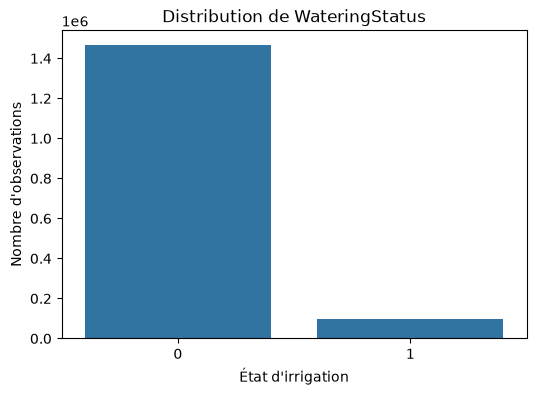

In [8]:
if "WateringStatus" not in df.columns:
    raise ValueError("La colonne 'WateringStatus' est absente du fichier.")

print("Distribution de la cible (valeurs incluses) :")
print(df["WateringStatus"].value_counts(dropna=False))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="WateringStatus")
plt.title("Distribution de WateringStatus")
plt.xlabel("État d'irrigation")
plt.ylabel("Nombre d'observations")
plt.show()

## 4. Préparer la cible et les variables explicatives

On conserve uniquement les lignes dont `WateringStatus` vaut 0 ou 1. Toute autre valeur (par exemple `251`) est mise à l'écart de cette classification binaire : il faut vérifier sa signification dans la source des données.

On utilise les variables environnementales et temporelles préparées dans le Feature Engineering. Les colonnes techniques, les identifiants et les mesures directement liées à l'écoulement/volume d'eau sont exclues pour limiter les fuites d'information (data leakage).

In [9]:
# Garder uniquement les observations dont la cible est connue et binaire
df_model = df[df["WateringStatus"].isin([0, 1])].copy()

print("Dimensions après sélection des classes 0 et 1 :", df_model.shape)
print("Répartition des classes :")
print(df_model["WateringStatus"].value_counts())

Dimensions après sélection des classes 0 et 1 : (1562765, 11)
Répartition des classes :
WateringStatus
0    1465740
1      97025
Name: count, dtype: int64


In [10]:
# Liste des variables candidates présentes dans le fichier
candidate_features = [
    "temp", "hum", "moistureLevel", "pres",
    "hour", "month", "day_of_week", "is_weekend",
    "hour_sin", "hour_cos"
]

feature_columns = [col for col in candidate_features if col in df_model.columns]

if not feature_columns:
    raise ValueError(
        "Aucune variable attendue n'a été trouvée. Vérifie les colonnes du fichier "
        "et adapte candidate_features."
    )

X = df_model[feature_columns].copy()
y = df_model["WateringStatus"].astype(int)

# Convertir les variables explicatives en valeurs numériques
X = X.apply(pd.to_numeric, errors="coerce")

print("Variables utilisées :", feature_columns)
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
display(X.head())
display(y.head())

Variables utilisées : ['temp', 'hum', 'moistureLevel', 'pres', 'hour', 'month', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos']
Dimensions de X : (1562765, 10)
Dimensions de y : (1562765,)


,temp,hum,moistureLevel,pres,hour,month,day_of_week,is_weekend,hour_sin,hour_cos
0,31.91,26.37,1024,963.92,16,4,0,0,-0.866025,-0.5
1,31.94,26.25,811,963.90,16,4,0,0,-0.866025,-0.5
2,31.96,26.04,1024,963.93,16,4,0,0,-0.866025,-0.5
3,31.99,25.83,895,963.92,16,4,0,0,-0.866025,-0.5
4,31.97,25.08,1024,963.90,16,4,0,0,-0.866025,-0.5


0    1
1    1
2    1
3    1
4    1
Name: WateringStatus, dtype: int64

## 5. Diviser les données en Train et Test

Le jeu de test sert à évaluer les modèles sur des observations qu'ils n'ont pas utilisées pendant l'entraînement. `stratify=y` conserve autant que possible la proportion des deux classes dans les deux ensembles.

Pour des données temporelles, une séparation chronologique est souvent préférable. Ici, on commence avec une séparation stratifiée aléatoire ; une validation chronologique pourra être ajoutée si les lignes sont ordonnées dans le temps.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("\nRépartition des classes dans y_train :")
print(y_train.value_counts(normalize=True))
print("\nRépartition des classes dans y_test :")
print(y_test.value_counts(normalize=True))

X_train : (1250212, 10)
X_test  : (312553, 10)

Répartition des classes dans y_train :
WateringStatus
0    0.937915
1    0.062085
Name: proportion, dtype: float64

Répartition des classes dans y_test :
WateringStatus
0    0.937915
1    0.062085
Name: proportion, dtype: float64


## 6. Construire les pipelines de prétraitement

- Les valeurs manquantes sont remplacées par la médiane, calculée uniquement sur les données d'entraînement.
- La normalisation est appliquée à la régression logistique.
- Les arbres de décision et Random Forest n'ont généralement pas besoin de normalisation.

L'utilisation de `Pipeline` évite d'apprendre les paramètres de prétraitement à partir du jeu de test.

In [12]:
numeric_features = X_train.columns.tolist()

linear_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

## 7. Entraîner les modèles

On compare trois algorithmes. `class_weight="balanced"` aide les modèles à tenir compte d'un éventuel déséquilibre entre les classes.

In [13]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessing", linear_preprocessor),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessing", tree_preprocessor),
        ("model", DecisionTreeClassifier(
            class_weight="balanced", random_state=42, max_depth=10
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessing", tree_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            random_state=42, n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} : entraînement terminé")

Logistic Regression : entraînement terminé
Decision Tree : entraînement terminé
Random Forest : entraînement terminé


## 8. Évaluer et comparer les modèles

L'accuracy seule peut être trompeuse si une classe est beaucoup plus fréquente que l'autre. On regarde également la précision, le rappel et le F1-score, en particulier pour la classe positive (`1`).

In [14]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df)

,Modèle,Accuracy,Precision,Recall,F1-score
2,Random Forest,0.996673,0.951073,0.997733,0.973844
1,Decision Tree,0.961274,0.617112,0.991291,0.760677
0,Logistic Regression,0.791293,0.219125,0.921206,0.354036


<Figure size 900x500 with 0 Axes>

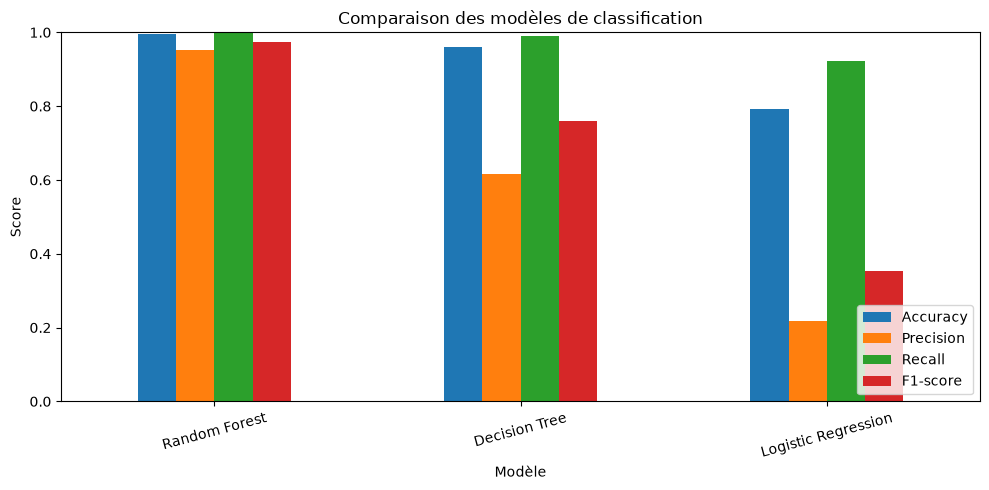

In [15]:
plt.figure(figsize=(9, 5))
results_plot = results_df.set_index("Modèle")[["Accuracy", "Precision", "Recall", "F1-score"]]
results_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Comparaison des modèles de classification")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Examiner le meilleur modèle

On choisit ici le modèle avec le meilleur F1-score sur le jeu de test comme comparaison initiale. Pour une évaluation finale rigoureuse, il faudra aussi utiliser une validation croisée ou un jeu de validation séparé, puis garder le test final intact.

In [16]:
best_model_name = results_df.iloc[0]["Modèle"]
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

print("Meilleur modèle selon le F1-score :", best_model_name)
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_best, zero_division=0))

Meilleur modèle selon le F1-score : Random Forest

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    293148
           1       0.95      1.00      0.97     19405

    accuracy                           1.00    312553
   macro avg       0.98      1.00      0.99    312553
weighted avg       1.00      1.00      1.00    312553



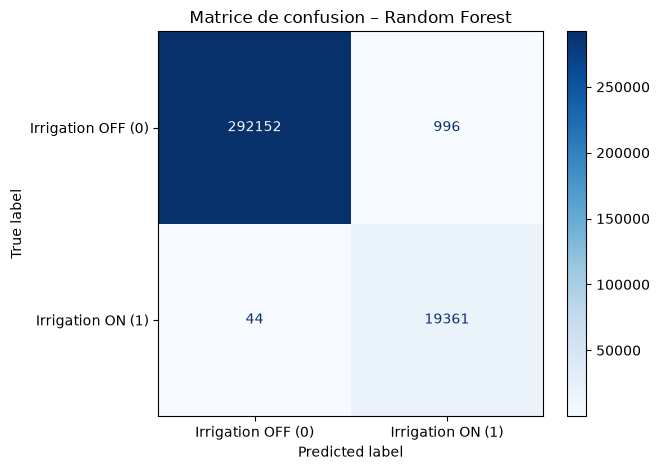

In [17]:
cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Irrigation OFF (0)", "Irrigation ON (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matrice de confusion – {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Conclusion à compléter

Après avoir exécuté le notebook, compléter les points suivants avec les résultats obtenus :

1. Quel modèle a obtenu le meilleur F1-score ?
2. Est-ce que le modèle détecte correctement la classe `1` (irrigation activée) ?
3. Quel est son rappel pour la classe `1` ?
4. Quelles erreurs observe-t-on dans la matrice de confusion ?
5. Les résultats sont-ils suffisants pour envisager une utilisation réelle ?

> Important : ce modèle est un prototype académique. Avant toute utilisation réelle, il faut vérifier les unités et la signification des capteurs, contrôler les anomalies et tester le modèle sur des données plus récentes.

## 11. Sauvegarder le meilleur modèle (facultatif)

Cette cellule enregistre le pipeline complet, y compris le prétraitement. Le fichier pourra être réutilisé dans une application de démonstration.

In [18]:
import joblib
from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

model_path = output_dir / "best_classification_model.joblib"
joblib.dump(best_model, model_path)

print("Modèle sauvegardé dans :", model_path)

Modèle sauvegardé dans : results\best_classification_model.joblib
